In [17]:
import pandas as pd
import matplotlib.pyplot as plt

In [18]:
df = pd.read_csv("/content/Retail_Sales_data - Retail_Sales_data.csv")

In [19]:
df.head(8)

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon
5,I227836,C657758,Female,28,Clothing,5,1500.40,Credit Card,24/05/2022,Forum Istanbul
6,I121056,C151197,Female,49,Cosmetics,1,40.66,Cash,13/03/2022,Istinye Park
7,I293112,C176086,Female,32,Clothing,2,600.16,Credit Card,13/01/2021,Mall of Istanbul


In [20]:
df.shape

(99457, 10)

In [21]:
df.columns

Index(['invoice_no', 'customer_id', 'gender', 'age', 'category', 'quantity',
       'price', 'payment_method', 'invoice_date', 'shopping_mall'],
      dtype='object')

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99457 entries, 0 to 99456
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_no      99457 non-null  object 
 1   customer_id     99457 non-null  object 
 2   gender          99457 non-null  object 
 3   age             99457 non-null  int64  
 4   category        99457 non-null  object 
 5   quantity        99457 non-null  int64  
 6   price           99457 non-null  float64
 7   payment_method  99457 non-null  object 
 8   invoice_date    99457 non-null  object 
 9   shopping_mall   99457 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 7.6+ MB


In [23]:
df.describe()

,age,quantity,price
count,99457.000000,99457.000000,99457.000000
mean,43.427089,3.003429,689.256321
std,14.990054,1.413025,941.184567
min,18.000000,1.000000,5.230000
25%,30.000000,2.000000,45.450000
50%,43.000000,3.000000,203.300000
75%,56.000000,4.000000,1200.320000
max,69.000000,5.000000,5250.000000


In [24]:
df.isnull().sum()

,0
invoice_no,0
customer_id,0
gender,0
age,0
category,0
quantity,0
price,0
payment_method,0
invoice_date,0
shopping_mall,0


In [25]:
print("Shopping Mall:")
df["shopping_mall"].head()

Shopping Mall:


,shopping_mall
0,Kanyon
1,Forum Istanbul
2,Metrocity
3,Metropol AVM
4,Kanyon


In [26]:
print("\nProduct Category:")
df["category"].head()


Product Category:


,category
0,Clothing
1,Shoes
2,Clothing
3,Shoes
4,Books


In [27]:
print("\nQuantity:")
df["quantity"].head()



Quantity:


,quantity
0,5
1,3
2,1
3,5
4,4


In [28]:
print("\nPrice:")
df["price"].head()


Price:


,price
0,1500.40
1,1800.51
2,300.08
3,3000.85
4,60.60


In [29]:
df["sales_amount"] = df["quantity"] * df["price"]

df[["shopping_mall", "category", "quantity", "price", "sales_amount"]].head()

,shopping_mall,category,quantity,price,sales_amount
0,Kanyon,Clothing,5,1500.40,7502.00
1,Forum Istanbul,Shoes,3,1800.51,5401.53
2,Metrocity,Clothing,1,300.08,300.08
3,Metropol AVM,Shoes,5,3000.85,15004.25
4,Kanyon,Books,4,60.60,242.40


In [30]:
mall_sales = df.groupby("shopping_mall")["sales_amount"].sum().reset_index()

print("Total Sales Amount by Shopping Mall:")
print(mall_sales)

Total Sales Amount by Shopping Mall:
       shopping_mall  sales_amount
0        Cevahir AVM   12645138.20
1  Emaar Square Mall   12406100.29
2     Forum Istanbul   12303921.24
3       Istinye Park   24618827.68
4             Kanyon   50554231.10
5   Mall of Istanbul   50872481.68
6          Metrocity   37302787.33
7       Metropol AVM   25379913.19
8     Viaport Outlet   12521339.72
9       Zorlu Center   12901053.82


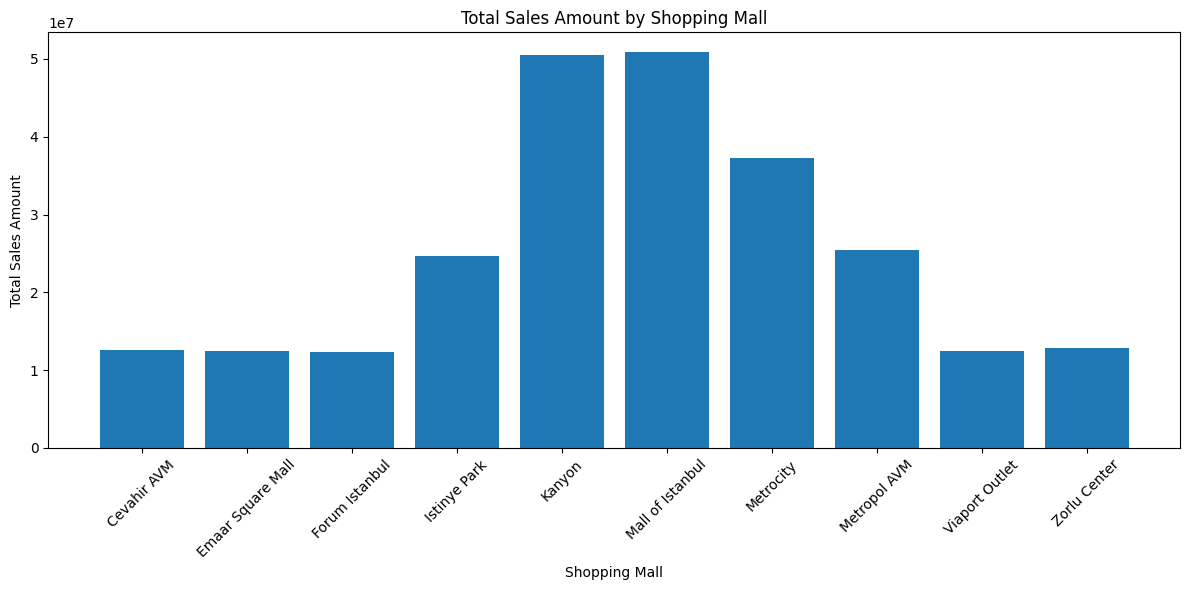

In [31]:
plt.figure(figsize=(12, 6))

plt.bar(mall_sales["shopping_mall"], mall_sales["sales_amount"])

plt.xlabel("Shopping Mall")
plt.ylabel("Total Sales Amount")
plt.title("Total Sales Amount by Shopping Mall")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

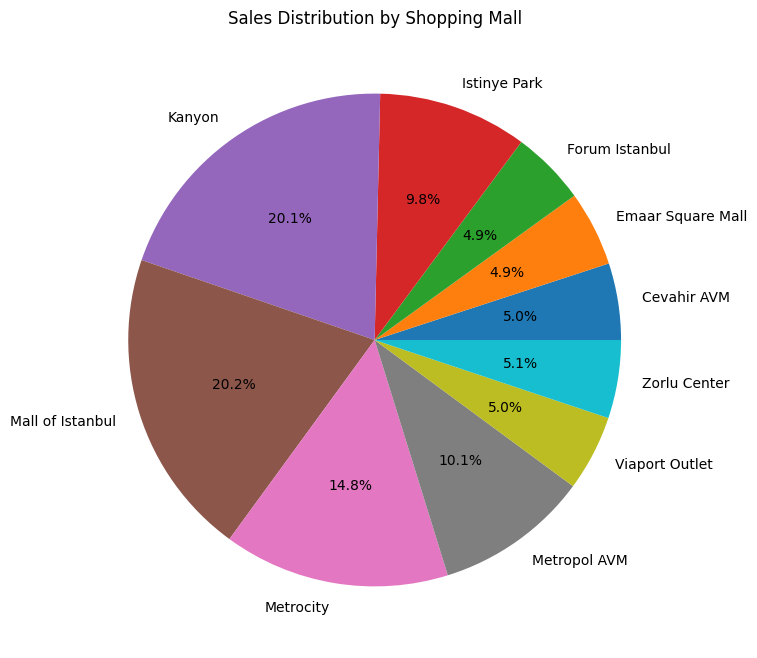

In [32]:
plt.figure(figsize=(8, 8))

plt.pie(
    mall_sales["sales_amount"],
    labels=mall_sales["shopping_mall"],
    autopct="%1.1f%%"
)

plt.title("Sales Distribution by Shopping Mall")
plt.show()

In [33]:
top_malls = mall_sales.sort_values(
    by="sales_amount",
    ascending=False
)

print("Top-Performing Shopping Malls:")
print(top_malls)

print("\nTop 5 Shopping Malls:")
print(top_malls.head(5))

Top-Performing Shopping Malls:
       shopping_mall  sales_amount
5   Mall of Istanbul   50872481.68
4             Kanyon   50554231.10
6          Metrocity   37302787.33
7       Metropol AVM   25379913.19
3       Istinye Park   24618827.68
9       Zorlu Center   12901053.82
0        Cevahir AVM   12645138.20
8     Viaport Outlet   12521339.72
1  Emaar Square Mall   12406100.29
2     Forum Istanbul   12303921.24

Top 5 Shopping Malls:
      shopping_mall  sales_amount
5  Mall of Istanbul   50872481.68
4            Kanyon   50554231.10
6         Metrocity   37302787.33
7      Metropol AVM   25379913.19
3      Istinye Park   24618827.68


In [34]:
mall_category_sales = df.groupby(
    ["shopping_mall", "category"]
)["sales_amount"].sum().reset_index()

print("Sales by Shopping Mall and Product Category:")
print(mall_category_sales)

Sales by Shopping Mall and Product Category:
   shopping_mall         category  sales_amount
0    Cevahir AVM            Books      44541.00
1    Cevahir AVM         Clothing    5706321.28
2    Cevahir AVM        Cosmetics     321214.00
3    Cevahir AVM  Food & Beverage      44010.45
4    Cevahir AVM            Shoes    3243918.85
..           ...              ...           ...
75  Zorlu Center  Food & Beverage      41955.06
76  Zorlu Center            Shoes    3535601.47
77  Zorlu Center         Souvenir      28996.56
78  Zorlu Center       Technology    2987250.00
79  Zorlu Center             Toys     197550.08

[80 rows x 3 columns]


In [35]:
pivot_data = mall_category_sales.pivot(
    index="shopping_mall",
    columns="category",
    values="sales_amount"
)

pivot_data

category,Books,Clothing,Cosmetics,Food & Beverage,Shoes,Souvenir,Technology,Toys
shopping_mall,,,,,,,,
Cevahir AVM,44541.00,5706321.28,321214.00,44010.45,3243918.85,29723.82,3051300.0,204108.80
Emaar Square Mall,41995.80,5590490.40,338941.76,40610.95,3089675.16,30943.74,3094350.0,179092.48
Forum Istanbul,42056.40,5792444.24,353172.76,39162.24,3327942.65,32879.19,2516850.0,199413.76
Istinye Park,76083.30,11253900.24,655357.88,85918.44,6641481.22,68925.48,5436900.0,400261.12
Kanyon,163029.15,22609527.60,1369550.78,166497.05,13383190.83,127399.53,11944800.0,790236.16
Mall of Istanbul,172240.35,22947417.68,1367517.78,171177.90,13467814.80,127540.29,11828250.0,790522.88
Metrocity,125911.65,17226692.56,991860.04,129902.74,9519296.37,94227.09,8608950.0,605946.88
Metropol AVM,83718.90,11568084.00,680770.38,88638.04,7149825.21,67869.78,5327700.0,413306.88
Viaport Outlet,39632.40,5604594.16,347439.70,41662.18,3194704.91,27319.17,3066000.0,199987.20


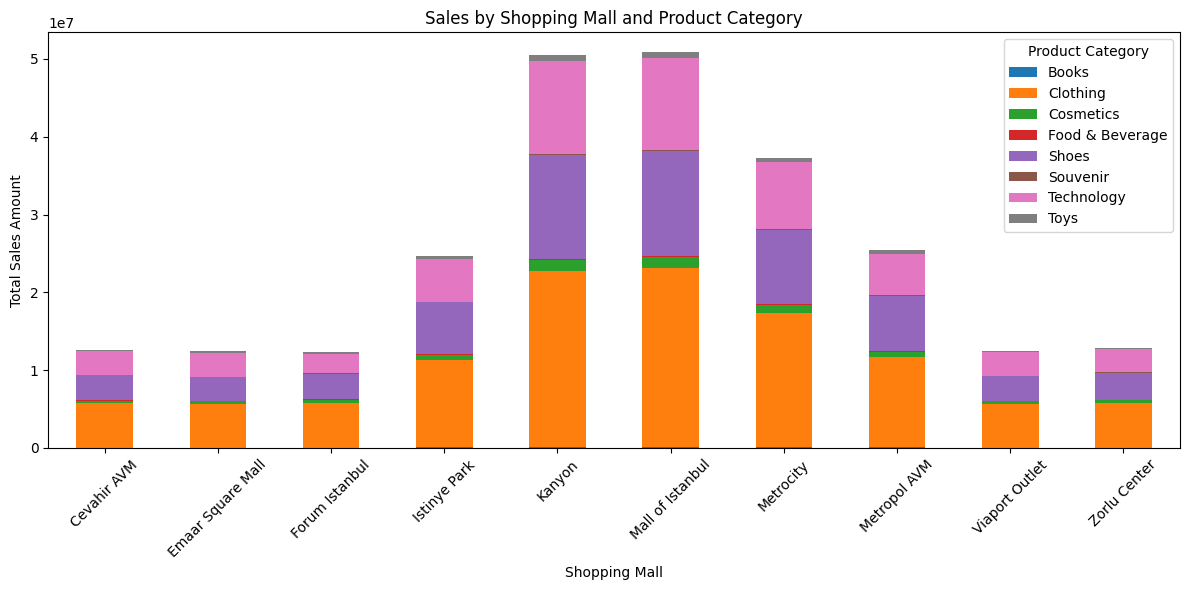

In [36]:
pivot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.xlabel("Shopping Mall")
plt.ylabel("Total Sales Amount")
plt.title("Sales by Shopping Mall and Product Category")

plt.xticks(rotation=45)
plt.legend(title="Product Category")
plt.tight_layout()
plt.show()

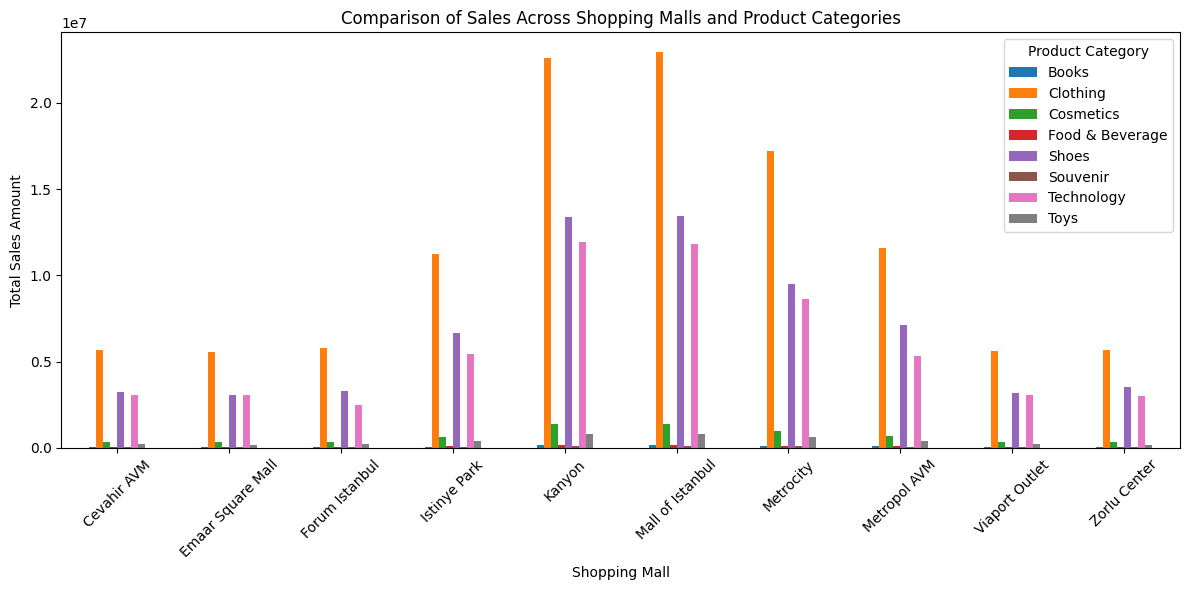

In [37]:
pivot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Shopping Mall")
plt.ylabel("Total Sales Amount")
plt.title("Comparison of Sales Across Shopping Malls and Product Categories")

plt.xticks(rotation=45)
plt.legend(title="Product Category")
plt.tight_layout()
plt.show()